# **Projet de fin de module**

**Module:**  Recherche opérationelle et optimisation

**Réalisé par:  ECH.CHNAOUI Nohaila**

**filière :**  CCN

## Introduction

Ce projet s'inscrit dans le cadre du module Recherche opérationelle et optimisation. l'objectif de ce projet est d'appliquer les principaux concepts étudié durant le semestre sur un cas réel.

Ce travail est divisé en 2 partie principale


nous avons choisi d'étudier le réseau routier du royaume-uni. l'analyse de ce réseau par la théorie des graphes pour analyser l'accessibilité global et optimiser les coûts.



# **Partie I – Structures, modélisation et parcours de graphes**

pour la partie I nous avons choisi le dataset réel du réseau de transport du royaume-uni (**UK Road Network Dataset**)

vous pouvez trouvez ci-joint le dataset:
https://www.kaggle.com/datasets/omenkj/uk-road-network-dataset/data?select=uk_road_network_dataset.csv



nous avons travaillé sur le fichier uk_road_network_dataset.csv



**Nettoyage du dataset**



In [271]:
import pandas as pd

reseau = pd.read_csv("uk_road_network_dataset.csv")
print(reseau.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9694 entries, 0 to 9693
Data columns (total 31 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   edge_id                 9694 non-null   object 
 1   source_node_id          9694 non-null   object 
 2   dest_node_id            9694 non-null   object 
 3   source_latitude         9694 non-null   float64
 4   source_longitude        9694 non-null   float64
 5   dest_latitude           9694 non-null   float64
 6   dest_longitude          9694 non-null   float64
 7   source_nearest_city     9694 non-null   object 
 8   dest_nearest_city       9694 non-null   object 
 9   road_name               9694 non-null   object 
 10  road_type               9694 non-null   object 
 11  road_type_description   9694 non-null   object 
 12  speed_limit_mph         9694 non-null   int64  
 13  distance_km             9694 non-null   float64
 14  travel_time_minutes     9694 non-null   

On constate à partir de ce fichier csv que: le dataset contient la

1.   les données represente des information détaillé sur la localisation du point source et destination des arretes (Edge) (latitue et longtitude)
2.   Éxistence du colonne is_bidirectional ce qui confirme que la direction est bien établie et n'est pas symétrique

3. le source et la destinations sont tous les deux caractérisé par "nearest_city" et la distance entre les deux est bien confirmé par "distance_km"

le nombre de sommet est 6 et les sommets sont:

In [272]:
villes = ["London","Manchester","Birmingham","Liverpool","Cardiff","Oxford"]

In [273]:
mini_reseau = reseau[
    (reseau["source_nearest_city"].isin(villes)) &
    (reseau["dest_nearest_city"].isin(villes))
]

t = []
for _, row in mini_reseau.iterrows():
    t.append([row["source_nearest_city"], row["dest_nearest_city"], row["distance_km"]])
    if row["is_bidirectional"]:
        t.append([row["dest_nearest_city"], row["source_nearest_city"], row["distance_km"]])

mini_edges = pd.DataFrame(t, columns=["source","dest","weight"])
mini_edges["weight"] = mini_edges["weight"].astype(int)



In [274]:
# on supprime les arretes qui sont dans la même ville pour eviter les boucles
mini_edges = mini_edges[mini_edges["source"] != mini_edges["dest"]]
print(mini_edges)

        source        dest  weight
0   Manchester     Cardiff     186
1      Cardiff  Manchester     186
2       Oxford     Cardiff     110
3    Liverpool  Manchester      49
4      Cardiff  Manchester     237
..         ...         ...     ...
80      London     Cardiff     215
81  Manchester   Liverpool     179
82   Liverpool  Manchester     179
85  Birmingham     Cardiff     112
90  Birmingham   Liverpool     222

[77 rows x 3 columns]


On constate que les arretes existants entre nos sommets sont de nombre 25 ce qui montre que ce graphe est un graphe très dense mais pas complet car

pour un graph orienté on a:
n= 6 (nombre de sommet)

le nombre maximal des arrets possible est
M= n (n-1) = 30 > 25



ça reste très dense alors on va focalisé notre étude sur le graphe partiel de ce graphe

In [275]:
# on garde une seule arrete entre 2 ville pour eliminer la possiblite d'avoir 2 diff passage entre 2 ville à partir 2 garre diff par garder celle avec la plus petite distance
df = mini_edges.sort_values("weight").drop_duplicates(subset=["source","dest"], keep="first")
print(df)

        source        dest  weight
19   Liverpool  Manchester      36
18  Manchester   Liverpool      36
57  Birmingham      Oxford      70
58      Oxford  Birmingham      70
47      Oxford      London      76
48      London      Oxford      76
23  Birmingham  Manchester     108
24  Manchester  Birmingham     108
2       Oxford     Cardiff     110
85  Birmingham     Cardiff     112
78      London  Birmingham     125
31   Liverpool  Birmingham     125
32  Birmingham   Liverpool     125
79  Birmingham      London     125
9      Cardiff  Birmingham     126
49  Manchester      Oxford     180
1      Cardiff  Manchester     186
0   Manchester     Cardiff     186
45      London     Cardiff     189
46     Cardiff      London     189
69     Cardiff   Liverpool     211
36      Oxford  Manchester     211
25   Liverpool     Cardiff     222
7    Liverpool      Oxford     241
8       Oxford   Liverpool     241
63      London  Manchester     256
62  Manchester      London     256
11   Liverpool      

In [276]:
df = df.sort_values("weight")

df = (
    df.groupby("source", group_keys=False)
      .apply(lambda g: g.nsmallest(2, "weight"))
)

print(df)


        source        dest  weight
57  Birmingham      Oxford      70
23  Birmingham  Manchester     108
9      Cardiff  Birmingham     126
1      Cardiff  Manchester     186
19   Liverpool  Manchester      36
31   Liverpool  Birmingham     125
48      London      Oxford      76
78      London  Birmingham     125
18  Manchester   Liverpool      36
24  Manchester  Birmingham     108
58      Oxford  Birmingham      70
47      Oxford      London      76


/tmp/ipykernel_4725/2450973769.py:5: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.nsmallest(2, "weight"))


 **1. Présentation du problème**

Le dataset représente le réseau routière du royaume_uni (UK)

Ce graphe est orienté ( les directions sont asymétriques) et pondéré (avec des distances bien défini) c'est pour cela


Après extraction de ces information le choix le plus adapté pour représenté ce dataset est par utilisé un graphe orienté car la direction est bien établie et n'est pas symétrique et pondéré avec des poids qui sont lié aux distance de parcours


On va focalisé notre travail juste sur les 6 grands villes du royaume-uni suivant:

**Modelisation du graphe**

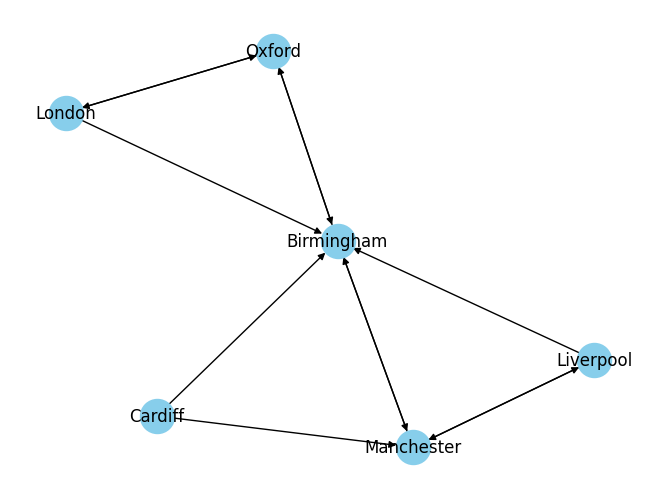

In [277]:
import networkx as nx
import matplotlib.pyplot as plt

G = nx.DiGraph()
for _, row in df.iterrows():
    G.add_edge(row["source"], row["dest"])

pos = nx.spring_layout(G, seed=42)
nx.draw(G, pos, with_labels=True, node_size=600, node_color="skyblue", arrows=True)
plt.show()

**identification des sommets et arcs ou arretes**


nos **sommets** sont:
 London, Manchester, Birmingham, liverpool, cardiff et Oxford



pour les **arcs**


 nous avons 12 qui connect les 6 sommets avec des poids positives

(Birmingham, Manchester) → 108

(Birmingham, Oxford) → 70

(Cardiff, Birmingham) → 126

(Cardiff, Manchester) → 186

(Liverpool, Birmingham) → 125

(Liverpool, Manchester) → 36

(London, Birmingham) → 125

(London, Oxford) → 76

(Manchester, Birmingham) → 108

(Manchester, Liverpool) → 36

(Oxford, Birmingham) → 70

(Oxford, London) → 76

**nature de graphe**: orienté pondéré

**3- Etude des propriété du graphe**

ce graphe est un graphe

1.   simplicité: cest un graphe **simple** on a un seul arc entre 2 sommets et on a pas des boucles
2.   Connexité: le graphe est faiblement connexe car on constate qu'il y a juste des arcs sortants du cardiff vers les autres villes et aucun arc entrant dont on peut pas aller vers cardiff à partir des autres villes
mais si on ignore les directions tous les sommets sont reliés donc c'est un graphe **faiblement connexe**
3. composantes : on constate l'existance de plusieurs composants comme entre liverpool, manchester et birmingham qui est fortement connecte
4. cycle: le grpahe contient des cycles (oxford->london ->birmingham->oxford)
5. structure arborescence: non le graphe contient des cycle donc ce n'est pas un arbre
6. DAG: le graphe n'est pas un DAG il contient des cycles



**3-Représentation marchine**

In [278]:
#par matrice adjacence

In [279]:
import numpy as np

sommets = sorted(set(df["source"]).union(set(df["dest"])))
sommet_index = {sommet: i for i, sommet in enumerate(sommets)}

n= len(sommets)
matrice_adj = np.zeros((n,n), dtype=int)


for _, row in df.iterrows():
    i, j = sommet_index[row["source"]], sommet_index[row["dest"]]
    matrice_adj[i][j] = 1

In [280]:
print(matrice_adj)

[[0 0 0 0 1 1]
 [1 0 0 0 1 0]
 [1 0 0 0 1 0]
 [1 0 0 0 0 1]
 [1 0 1 0 0 0]
 [1 0 0 1 0 0]]


In [281]:
matrice = pd.DataFrame(matrice_adj, index=sommet_index, columns=sommet_index)
print(matrice)


            Birmingham  Cardiff  Liverpool  London  Manchester  Oxford
Birmingham           0        0          0       0           1       1
Cardiff              1        0          0       0           1       0
Liverpool            1        0          0       0           1       0
London               1        0          0       0           0       1
Manchester           1        0          1       0           0       0
Oxford               1        0          0       1           0       0


In [282]:
mat_pondéré = np.zeros((n,n), dtype=int)

for _, row in df.iterrows():
    i, j = sommet_index[row["source"]], sommet_index[row["dest"]]
    mat_pondéré[i][j] = row["weight"]
print(mat_pondéré)

[[  0   0   0   0 108  70]
 [126   0   0   0 186   0]
 [125   0   0   0  36   0]
 [125   0   0   0   0  76]
 [108   0  36   0   0   0]
 [ 70   0   0  76   0   0]]


In [283]:
print("\n la iste d'adjacence:")
for i, sommet in enumerate(sommets):
    voisins = [sommets[j] for j in range(n) if matrice.iloc[i, j] == 1]
    print(f"{sommet} -> {voisins}")


 la iste d'adjacence:
Birmingham -> ['Manchester', 'Oxford']
Cardiff -> ['Birmingham', 'Manchester']
Liverpool -> ['Birmingham', 'Manchester']
London -> ['Birmingham', 'Oxford']
Manchester -> ['Birmingham', 'Liverpool']
Oxford -> ['Birmingham', 'London']


**5-comparaison entre les deux représentations**


la matrice adjacence occupe
n*n

de mémoire , donc 6 x 6= 36 pour notre graphe
alors que la representation par liste occupe n +m donc juste 12 + 6 = 18 donc la liste est plus optimale coté mémoire


pour accès direct à un arc spécifique il faut juste parcourir les voisin dans le cas de liste alors que la matrice est plus couteux

donc la liste reste plus optimale que la matrice dans un graphe comme ceci analysé dans ce projet car la matrice peut gaspillr plus de ressource mais peut etre plus adapté dans le cas d'application de quleque algorithme comme warshall

En somme dans le cas étudié la liste d'adjascence reste le choix le plus efficace pour l'exploration de structure tandis que la matrice peut etre conservé pour calcul algorithmique particuliers


**6- application de dfs et bfs**

**DFS**

on commencre par le parcour en profondeur puisque cardiff est la seule ville juste avec les arcs sortant on la choisi comme sommet de départ.

Dans le mécanisme DFS:
on commence par empiler Cardiff puis explorer ses adjacent


P =[Cardiff]

On choisit bilmingham et l'empile ensuite et après empile un voisin de bilmingham aussi

P =[Cardiff, Bilmingham]

On continue meme exploration en profondeur par plonger vers oxford l'empiler et apres london

P= [Cardiff, Bilmingham, Oxford, London]

london ne trouve plus des voisin a visiter il retourn vers oxford , retourn vers bilmingham pui va plonger vers manchester et nfin liverpool  

P= [Cardiff, Bilmingham, Oxford, London, Manchester, Liverpool]

On peut vérifier le mécanisme par code suivant

In [284]:
# on crée un dictionnaire pour faciliter utilisation des données du graphe

In [285]:
dict = {}
for i, sommet in enumerate(sommets):
    voisins = [sommets[j] for j in range(n) if matrice.iloc[i, j] == 1]
    dict[sommet] = [v for v in voisins]
print(dict)


{'Birmingham': ['Manchester', 'Oxford'], 'Cardiff': ['Birmingham', 'Manchester'], 'Liverpool': ['Birmingham', 'Manchester'], 'London': ['Birmingham', 'Oxford'], 'Manchester': ['Birmingham', 'Liverpool'], 'Oxford': ['Birmingham', 'London']}


In [286]:
def DFS(graph, start, visited=None):
    if visited is None:
        visited = set()
    visited.add(start)
    print(start, end=" ")
    for voisin in graph[start]:
        if voisin not in visited:
            DFS(graph, voisin, visited)
    return visited

In [287]:
print("DFS depuis Cardiff :")
DFS(dict, "Cardiff")

DFS depuis Cardiff :
Cardiff Birmingham Manchester Liverpool Oxford London 

{'Birmingham', 'Cardiff', 'Liverpool', 'London', 'Manchester', 'Oxford'}

**BFS**

on commencre par le parcour en largeur depuis cardiff

Dans le mécanisme DFS:
on commence par ajouter Cardiff dans la file et enfiler ces voisin bilmingham et manchester ouis la marquer comme visité

F =[Cardiff, Bilmingham, Manchester]

On visite les voisin de bilminghal, enfiler les voisin puis defiler biminghal
apres on fait meme pour manchester et on continue jusqu'à passer par tous les soomets

l'ordre sera
Cardiff Birmingham Manchester Oxford Liverpool London

On utilise l code suivant

In [288]:
from collections import deque

def BFS(graph, start):
    visited = {start}
    queue = deque([start])
    while queue:
        node = queue.popleft()
        print(node, end=" ")
        for voisin in graph.get(node):
            if voisin not in visited:
                visited.add(voisin)
                queue.append(voisin)


In [289]:
print("\nBFS depuis Cardiff :")
BFS(dict, "Cardiff")


BFS depuis Cardiff :
Cardiff Birmingham Manchester Oxford Liverpool London 

**7-Exploitation du graphe**

on sait que le tri topologique s'applique uniquement sur les graphes non orienté acyclique (DAG), Or notre graphe contient des cycle qu'on a mentionné au début comme (oxford->london ->birmingham->oxford) donc application du TopoDAG n'est pas possible dans notre étude

Donc on va focaliser sur l'exploitation d'algorithm warshall pour les fermetures transitives

In [290]:
def warshall (M) :
 n = len(M)
 T = [ row [:] for row in M]
 for k in range ( n ) :
  for i in range ( n ) :
   for j in range ( n ) :
    T [i][j] = T [i][j] or ( T [i][k] and T [k][j])
 return T

L'application d'algorithme calcule la fermeture transitive en mettant à jour progressivement
la matrice d’accessibilité


In [291]:
print(matrice_adj)

[[0 0 0 0 1 1]
 [1 0 0 0 1 0]
 [1 0 0 0 1 0]
 [1 0 0 0 0 1]
 [1 0 1 0 0 0]
 [1 0 0 1 0 0]]


In [292]:
warshall(matrice_adj)

[array([1, 0, 1, 1, 1, 1]),
 array([1, 0, 1, 1, 1, 1]),
 array([1, 0, 1, 1, 1, 1]),
 array([1, 0, 1, 1, 1, 1]),
 array([1, 0, 1, 1, 1, 1]),
 array([1, 0, 1, 1, 1, 1])]

In [293]:
warsh = pd.DataFrame(matrice_adj, index=sommet_index, columns=sommet_index)
print(warsh)

            Birmingham  Cardiff  Liverpool  London  Manchester  Oxford
Birmingham           1        0          1       1           1       1
Cardiff              1        0          1       1           1       1
Liverpool            1        0          1       1           1       1
London               1        0          1       1           1       1
Manchester           1        0          1       1           1       1
Oxford               1        0          1       1           1       1


**8- Interpretation des résultats**

l'analyse de ce graphe et l'implémentation d'algorithm warshall montre que le sommet Cardiff reste un sommet périphérique puisqu'il possède juste des arcs sortants c'est pour cela qu'il n'est pas atteint par les autres villsx

l'obtention des 1 dans le reste de la matrice confirme que les autres 5 sommets forme une composante fortement connexe car tous les cinqs peut arriver aux autres sommets soit directement ou indirement

cela est aussi démontré à travers les parcours bfs et dfs qu'on a réalisé avant


On constate que l'application d'algorimthe ajoute indirectement tous les chemins possibles, maintenant tous les sommets du graphes sont accessible entre eux sauf sommet cardiff car aucun arc ne revient vers lui.


**Synthèse totale**

à partir notre dataset du réseau routière du royaume-uni (UK) on peut dire que le choix entre matrice et liste d'adjascence dépend de l'utilisation et la densité du graphe

premièrement pour notre graphe orienté commposé de 6 sommets. la complexité du matrice est n x n (36) alors que nous possédons uniquement 12 arc l'utilisation de liste d'adjascence reste le choix le plus optimale (6+12=18)

donc pour les parcours dfs et bfs on a basé le travail sur la liste pour réduire la consommation de la mémoire


D'autre part la matrice d'adjascence reste une structure très important surtout quand on a appliqué algorithme warshall qui se base directement sur cette structure

l'utilisation de la fermeture transitive a bien révélé plusieur informations pertinents sur notre graphe comme le fait que le sommet cardifs est impossible à atteindre à partir des autres sommets, aussi l'existence des cycles et que tous les autres sommets forme une composante connexe.

En somme la matrice est idéal pour la fermeture transitive tandis que les listes est préférables pour les parcous BFS et DFS.


# **Partie II – Optimisation, planification et décision sur graphes**

Dans cette partie de notre projet on va travailler sur le meme dataset routière mais cette fois on va se basé sur les disances en kilomètre trouvés sur le dataset pour détérminer le chemin le plus courts à partir d'un sommet précis

**1-définition du problème**

notre dataset s'agit du réseau du transport entre les villes du royaume-uni, le problème qu'on souhaite résoudre c'est de trouver l’itinéraire optimal entre une ville vers tous les autres villes

le graphes étudié est un graphe orienté et pondéré, les couts représente les distances en kilomètre


In [294]:
print(df)

        source        dest  weight
57  Birmingham      Oxford      70
23  Birmingham  Manchester     108
9      Cardiff  Birmingham     126
1      Cardiff  Manchester     186
19   Liverpool  Manchester      36
31   Liverpool  Birmingham     125
48      London      Oxford      76
78      London  Birmingham     125
18  Manchester   Liverpool      36
24  Manchester  Birmingham     108
58      Oxford  Birmingham      70
47      Oxford      London      76


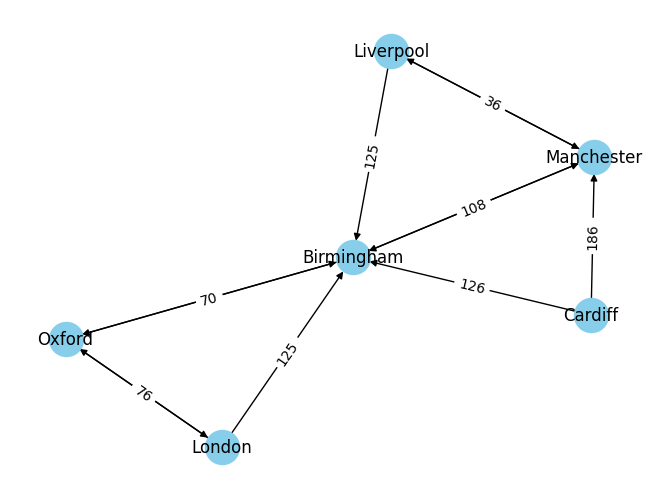

In [295]:
import networkx as nx
import matplotlib.pyplot as plt

G = nx.DiGraph()
for _, row in df.iterrows():
    G.add_edge(row["source"], row["dest"], weight=row["weight"])

pos = nx.spring_layout(G, seed=42)

nx.draw(G, pos, with_labels=True, node_size=600, node_color="skyblue", arrows=True)
edge_labels = nx.get_edge_attributes(G, "weight")
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels)

plt.show()


**2- choix de famille d'algorithme**

pour résoudre ce type de problème fondamental pour le transport et trouver la distance la plus minimale pour aller d'une ville vers les autres le choix le plus adapté est d'appliquer l'un des algorithmes du famile du plus court chemins (PCC) car cette famille offre plusieur solution adapté à notre graphe

1.  algorithme de Dijkstra (les poids sont tous des poids positif (toutes distances > 0) et la complexité est O (E log V)
2.   algorithme de bellman-ford





**3- la mise en oeuvre des algorithmes**

On va commencé par Diskstra car on sait que les poids sont tous des poids positif (toutes distances > 0) et la complexité est O (E log V)

In [296]:
graph = {}
for _, row in df.iterrows():
 u, v, w = row["source"], row["dest"], row["weight"]
 graph.setdefault(u, []).append((v, w))

In [297]:
print(graph)

{'Birmingham': [('Oxford', 70), ('Manchester', 108)], 'Cardiff': [('Birmingham', 126), ('Manchester', 186)], 'Liverpool': [('Manchester', 36), ('Birmingham', 125)], 'London': [('Oxford', 76), ('Birmingham', 125)], 'Manchester': [('Liverpool', 36), ('Birmingham', 108)], 'Oxford': [('Birmingham', 70), ('London', 76)]}


In [298]:
import heapq

def dijkstra ( graph , start ) :
 d = { u : float ("inf") for u in graph }
 parent = { u : None for u in graph }
 d [ start ] = 0
 pq = [(0 , start ) ]
 while pq :
  dist_u , u = heapq . heappop ( pq )
  if dist_u > d [ u ]:
   continue

  for v , w in graph [ u ]:
   if d [ v ] > d [ u ] + w :
    d [ v ] = d [ u ] + w
    parent [ v ] = u
    heapq . heappush ( pq , ( d [ v ] , v ) )

 return d , parent

In [299]:
dijkstra(graph,'Cardiff')

({'Birmingham': 126,
  'Cardiff': 0,
  'Liverpool': 222,
  'London': 272,
  'Manchester': 186,
  'Oxford': 196},
 {'Birmingham': 'Cardiff',
  'Cardiff': None,
  'Liverpool': 'Manchester',
  'London': 'Oxford',
  'Manchester': 'Cardiff',
  'Oxford': 'Birmingham'})

On trouve que les iténeraires les plus courts pour arriver aux villes à partir du Cardiff sont

1.   Birmingham : 126km directement à partir cardiff
2.   Oxford: 196km à partir Birmingham
3.   London : 272km à partir Oxford
4.   Manchester : 186km directement à partir cardiff
5.   Liverpool : 222km à partir de manchester au lieu de Birmingham

cet algorithme est le plus adapté et le plus optimale car la complexion est o ((m+n) * log(n))



**4- comparaison des approches**

le problème du plus court chemin a été abordé et résolu par plusieur algorithmes et approches

d'un coté certain essaie de determiner autre algorithmes et tous ces solutions sont basé soit sur le mécanisme bfs/dfs, relaxation, concept glutonne (comme dijkstra) ou programmation dynamique

**Algorithme bellman-kalaba**

pour cette algorithme l'application est impossible car il s'applique juste si le graphe est un DAG mais notre graphe contient des cycles comme vérifié dans la partie I

**Algorithme Bellman-Ford-moore**

pour l'application de bellmand ford il reste possible et nous permet de détecter l'existence des cycles négatif

Le principe de cet algorithme se base sur la relaxation

In [300]:
def bellman_ford_moore ( graph , start ) :
 d = { u : float ("inf") for u in graph }
 parent = { u : None for u in graph }
 d [start] = 0
 edges = []
 for u in graph :
  for v , w in graph [u]:
   edges . append (( u , v , w ) )
 n = len(graph)
 for _ in range ( n - 1) :
  updated = False
  for u , v , w in edges :
   if d [u] != float ("inf ") and d [ v ] > d [ u ] + w :
    d [v] = d [u] + w
    parent [v] = u
    updated = True
  if not updated :
   break
 for u , v , w in edges :
  if d [u] != float ("inf ") and d [v] > d [u] + w :
   raise ValueError (" Cycle negatif detecté")
 return d , parent

In [301]:
bellman_ford_moore(graph,'Cardiff')

({'Birmingham': 126,
  'Cardiff': 0,
  'Liverpool': 222,
  'London': 272,
  'Manchester': 186,
  'Oxford': 196},
 {'Birmingham': 'Cardiff',
  'Cardiff': None,
  'Liverpool': 'Manchester',
  'London': 'Oxford',
  'Manchester': 'Cardiff',
  'Oxford': 'Birmingham'})

On obtient le meme résultat des petit courts chemin à partir l'algorithme belmanford-moore ce qui assure que notre résultat est correct

**5- analyse de complexité**

on sait que la complexité d'algorithme dijkstra vaut

O((m+n)*log(n))


on a 6 sommets et 12 arcs donc



In [302]:
import math
(12+6)* math.log(6)

32.25167044610499

la complexité de bellman-ford vaut O(n*m)

In [303]:
12*6

72

On constate que les deux algorithmes sont rapide mais dijkstra est plus rapide est optimal



**6- interprétation de résultat**


 L’application de l’algorithme de Dijkstra sur le dataset routier britannique a permis de trouver les chemins optimaux depuis la ville Cardiff vers vers toutes les autres villes.

 Les résultats montrent que Birmingham et Manchester sont accessibles directement alors que les autres villes comme Liverpool, Oxford et London nécessitent des chemins indirects. Par exemple:
 1.  Cardiff → Manchester → Liverpool
 2. Cardiff → Birmingham → Oxford → London.

  Ces itinéraires minimisent la distance totale parcourue et constituent une aide à la décision pour les problèmes de  logistique car trouvr un chemin optimal réduit les couts de déplacement et permet aussi de gagner le temps ce qui peut par exemple améliorer performance des camions de transport d'une entreprise de livraison  

**7- les conditions d'application des algorithmes**

l'algorithme dijkstra reste le choix le plus adapté pour les problèmes des iténéraire PCC car il est plus rapide avec une compléxité de O((m+n)*log(n)) mais la seule limite c'est quil es incapable de détrminer le chemin le plus court dans un graphe avec poids négative mais dans notre étude ou les distances en km sont des valeurs positive cela reste le choix le plus adapté


pour surpasser cette limite l'application du Bellman‑Ford est la solution car cette algorithme peux gérer les poids négative, lautre avantage de bellman-ford est qui il est basé sur la prgramation dynamique

la limite de belman-ford cest qu'est tres loud que dijkstra lors d'application dans un graphes comme ceci (12 arcs) capable de gérer ce cas.

**Question de synthèse**

Sur le dataset réel étudié, le choix de l’algorithme de graphe le plus pertinent entre Prim, Dijkstra, Bellman-Ford, une méthode sur DAG, PERT.. dépend principalment du nature du graphe étudié et nature du problème

pour des problème lié ou iténairaire la famille PCC reste le meilleur choix, pour les probleme de minimisation des connexions les algorithmes d'arbre couvrant minimum comme prim est la solution. et pour probleme lié à l'ordonnencement et la dépendance es taches approcher la problématique avec PERT est plus mieux

pas seulement ca, la nature du graphe dataset elle meme joue un role important par exemple pour notre cas on n'est pas capable d'appliquer la méthode TOPO-DAG car notre graphe n'est pas acyclique chose qui a limité notre analyse, dans un autre dataset on peut constater des couts négatif ce qui peut empecher utilistation de Dijkstra

En somme le choix d'algorithme dépend principalement du nature du problème et dataset en main

#**Sythèse général final**

Pour passer dans un même projet, d’une modélisation théorique par les graphes à une résolution algorithmique rigoureuse, tout en choisissant pour chaque problème réel la structure, la représentation et l’algorithme les plus adaptés. on passe par étapes:

1. dabord on transforme une question bien établi en un modèle car le choix de modélisation vient avant penser aux algorithmes par observer les données qu'on a sous forme de datasets (tableaux) en des représentation visuels par des sommets et arcs (cas orienté) ou des arretes

2. le choix de modélisation doit etre aussi etre bien fait en fonction des sommets et connexion entre eux pour savoir dès le départ le meileur choix (matrice adjascence ou liste) ce choix peut etre effectuer facilement grace aux comparaison des complexité des deux modélisation


3. après la modélisation on doit bien élaborer le problème qu'on veut étudié est ce qu'il s'agit de problème d'ordonnemencement des taches ou de réduction de connexions..

4. après on commence à penser à l'algorithmes par déterminer le type du problème pour trouver la solution la plus adapté

4. la prise du décision d'algorithme doit etre effectuer à travers une étude comparative entre les algorithmes pour trouver le choix le plus adapté et on prend on considération les contraint de notre dataset (par ex: existence des cycles) et aussi les limites d'un algorithme (ex: l'incapacité d'etre appliquer sur des graphes avec poids negatives)

En somme ce processus peut récapituler comment on peut passer d’une abstraction mathématique (dataset réel des routes) à une solution opérationnelle à travers des algorithmes en choisissant la structure et l’approche les plus adaptées pour arriver à résoudre un problème réel et améliorer la performance (de vitesse de livraison par exemple)

cette cohérence méthodologique est la clé pour arriver à prendre la meilleure décision